<a href="https://colab.research.google.com/github/mohib08/machine_learning_revision/blob/main/codebasics_tutorial_1_(Linear_Regression).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# import buit-in dataset
from sklearn.datasets import fetch_california_housing

In [ ]:
# # Load a regression dataset (California Housing)
# housing = fetch_california_housing(as_frame=True)
# df = housing.frame

In [ ]:
from sklearn.datasets import load_diabetes

# This loads instantly offline without HTTP requests
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame
print(df.head())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


In [ ]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


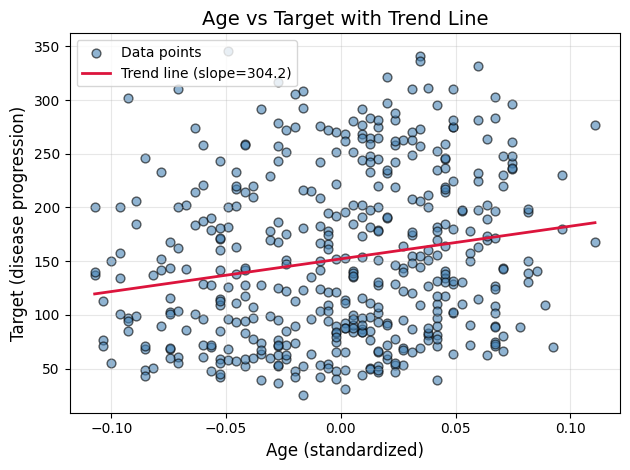

In [ ]:
y = df.target

# Age is the first feature (index 0)
age = df['age']

# Scatter plot
plt.scatter(age, y, alpha=0.6, color='steelblue',
            edgecolor='k', s=40, label='Data points')

# Fit and plot a linear trend line
z = np.polyfit(age, y, 1)
p = np.poly1d(z)
x_sorted = np.sort(age)
plt.plot(x_sorted, p(x_sorted), color='crimson', linewidth=2,
         label=f'Trend line (slope={z[0]:.1f})')

plt.xlabel('Age (standardized)', fontsize=12)
plt.ylabel('Target (disease progression)', fontsize=12)
plt.title('Age vs Target with Trend Line', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
X = df.drop(columns='target')
y = df['target']

In [ ]:
from sklearn.model_selection import train_test_split


X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.7,random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train,y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)


In [ ]:
y_pred.shape

(310,)

In [ ]:
test_r2 = model.score(X_test,y_test)
test_r2

0.4526027629719195

In [ ]:
train_r2 = model.score(X_train,y_train)
train_r2

0.5279193863361498

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error

In [ ]:
print("R² :", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred)**0.5)


R² : 0.4289089735881415
RMSE: 56.964762045682676


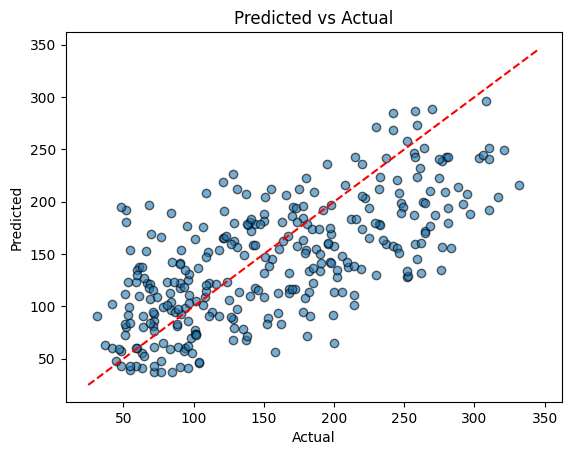

In [ ]:
plt.scatter(y_test, y_pred, alpha=0.6, edgecolor='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel('Actual'); plt.ylabel('Predicted'); plt.title('Predicted vs Actual')
plt.show()